In [1]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.shape)
print(df.dtypes)
print(df.head())
print(df.isnull().sum().sum())
print(df.duplicated().sum())
print(df["customerID"].nunique())

(7043, 21)
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45    

In [3]:
def load_data(path):
    dtypes = {
        "customerID": "string",
        "SeniorCitizen": "int64",
        "tenure": "int64",
        "MonthlyCharges": "float64",
        "TotalCharges": "string",   # has blanks, fixed later
    }
    cat_cols = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
                "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
                "PaperlessBilling", "PaymentMethod", "Churn"]
    for col in cat_cols:
        dtypes[col] = "category"
    return pd.read_csv(path, dtype=dtypes)

df_typed = load_data("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df_typed.dtypes)
print("memory with dtypes:", df_typed.memory_usage(deep=True).sum())
print("memory without dtypes:", df.memory_usage(deep=True).sum())

customerID            string
gender              category
SeniorCitizen          int64
Partner             category
Dependents          category
tenure                 int64
PhoneService        category
MultipleLines       category
InternetService     category
OnlineSecurity      category
OnlineBackup        category
DeviceProtection    category
TechSupport         category
StreamingTV         category
StreamingMovies     category
Contract            category
PaperlessBilling    category
PaymentMethod       category
MonthlyCharges       float64
TotalCharges          string
Churn               category
dtype: object
memory with dtypes: 1087464
memory without dtypes: 7152287


In [4]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
print(df["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [5]:
for col in df.columns:
    if df[col].nunique() < 10:
        print(col, list(df[col].unique()))

gender ['Female', 'Male']
SeniorCitizen [np.int64(0), np.int64(1)]
Partner ['Yes', 'No']
Dependents ['No', 'Yes']
PhoneService ['No', 'Yes']
MultipleLines ['No phone service', 'No', 'Yes']
InternetService ['DSL', 'Fiber optic', 'No']
OnlineSecurity ['No', 'Yes', 'No internet service']
OnlineBackup ['Yes', 'No', 'No internet service']
DeviceProtection ['No', 'Yes', 'No internet service']
TechSupport ['No', 'Yes', 'No internet service']
StreamingTV ['No', 'Yes', 'No internet service']
StreamingMovies ['No', 'Yes', 'No internet service']
Contract ['Month-to-month', 'One year', 'Two year']
PaperlessBilling ['Yes', 'No']
PaymentMethod ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn [np.int64(0), np.int64(1)]


In [6]:
blank = df["TotalCharges"].str.strip() == ""   #there was space and pandas consider space as not null
print(blank.sum())
print(df.loc[blank, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

11
      tenure  MonthlyCharges TotalCharges  Churn
488        0           52.55                   0
753        0           20.25                   0
936        0           80.85                   0
1082       0           25.75                   0
1340       0           56.05                   0
3331       0           19.85                   0
3826       0           25.35                   0
4380       0           20.00                   0
5218       0           19.70                   0
6670       0           73.35                   0
6754       0           61.90                   0


In [7]:
tc = pd.to_numeric(df["TotalCharges"], errors="coerce")  # coerce writes NaN

print(df[["tenure", "MonthlyCharges"]].describe())
print(tc.describe())
print(df[["tenure", "MonthlyCharges"]].skew().round(2))
print(round(tc.skew(), 2))

            tenure  MonthlyCharges
count  7043.000000     7043.000000
mean     32.371149       64.761692
std      24.559481       30.090047
min       0.000000       18.250000
25%       9.000000       35.500000
50%      29.000000       70.350000
75%      55.000000       89.850000
max      72.000000      118.750000
count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64
tenure            0.24
MonthlyCharges   -0.22
dtype: float64
0.96


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

eda = df.copy()
eda["TotalCharges"] = pd.to_numeric(eda["TotalCharges"], errors="coerce").fillna(0)
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

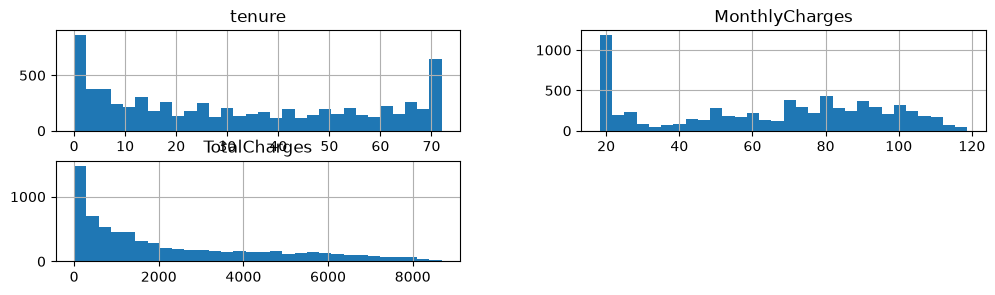

In [9]:
eda[num_cols].hist(bins=30, figsize=(12, 3))
plt.show()

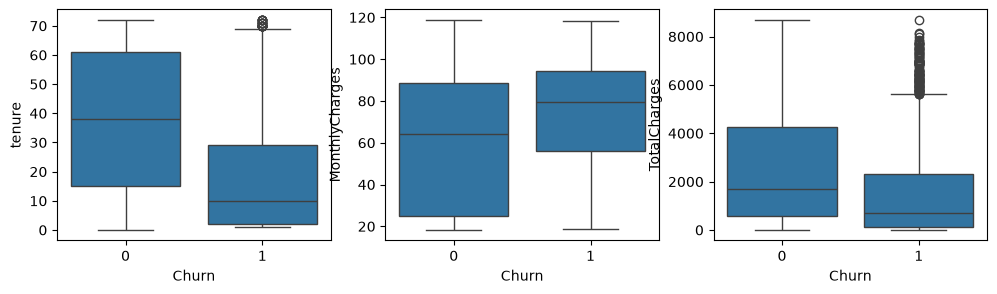

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for i, col in enumerate(num_cols):
    sns.boxplot(data=eda, x="Churn", y=col, ax=ax[i])
plt.show()

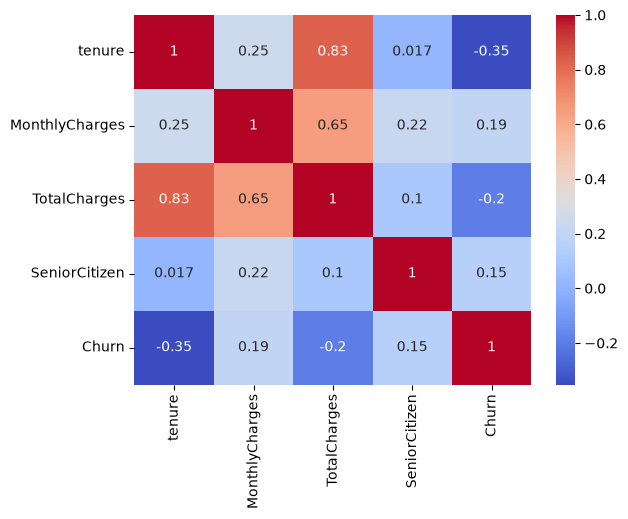

In [11]:
corr = eda[num_cols + ["SeniorCitizen", "Churn"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

In [12]:
for col in ["Contract", "InternetService", "PaymentMethod"]:
    print(eda.groupby(col)["Churn"].mean().round(3), "\n")

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64 

InternetService
DSL            0.190
Fiber optic    0.419
No             0.074
Name: Churn, dtype: float64 

PaymentMethod
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Electronic check             0.453
Mailed check                 0.191
Name: Churn, dtype: float64 



In [13]:
def clean_data(data):
    data = data.copy()
    # 1. TotalCharges blank -> 0 (new customers), then number
    data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce").fillna(0)
    # 2. "No internet service" / "No phone service" -> No
    cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies"]
    data[cols] = data[cols].replace({"No internet service": "No", "No phone service": "No"})
    # 3. Churn Yes/No -> 1/0
    data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})
    # 4. remove duplicate customers
    data = data.drop_duplicates(subset="customerID")
    return data

In [14]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

print(X.shape, y.shape)

(7043, 20) (7043,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = X_train.copy()
X_test = X_test.copy()

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

(5634, 20) (1409, 20)
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [16]:
print(X_train.duplicated().sum())
print(X_train.drop(columns=["customerID"]).duplicated().sum())

0
26


In [17]:
X_train = X_train.drop(columns=["customerID"])
X_test  = X_test.drop(columns=["customerID"])

print(X_train.shape, X_test.shape)

(5634, 19) (1409, 19)


In [18]:
X_train["TotalCharges"] = pd.to_numeric(X_train["TotalCharges"], errors="coerce")
X_test["TotalCharges"]  = pd.to_numeric(X_test["TotalCharges"],  errors="coerce")

print(X_train["TotalCharges"].isnull().sum(), X_test["TotalCharges"].isnull().sum())
print(X_train.loc[X_train["TotalCharges"].isnull(), "tenure"].unique())
print(X_test.loc[X_test["TotalCharges"].isnull(), "tenure"].unique())

8 3
[0]
[0]


In [19]:
X_train["TotalCharges"] = X_train["TotalCharges"].fillna(0)
X_test["TotalCharges"]  = X_test["TotalCharges"].fillna(0)

print(X_train.isnull().sum().sum(), X_test.isnull().sum().sum())
print(X_train["TotalCharges"].dtype)

0 0
float64


In [20]:
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((X_train[col] < lower) | (X_train[col] > upper)).sum()
    print(col, "| lower:", round(lower, 2), "| upper:", round(upper, 2), "| outliers:", count)

tenure | lower: -60.0 | upper: 124.0 | outliers: 0
MonthlyCharges | lower: -45.84 | upper: 171.51 | outliers: 0
TotalCharges | lower: -4746.3 | upper: 8985.1 | outliers: 0


In [21]:
print(pd.crosstab(X_train["InternetService"], X_train["OnlineSecurity"]))
print(pd.crosstab(X_train["PhoneService"], X_train["MultipleLines"]))

OnlineSecurity     No  No internet service  Yes
InternetService                                
DSL               985                    0  952
Fiber optic      1812                    0  671
No                  0                 1214    0
MultipleLines    No  No phone service   Yes
PhoneService                               
No                0               559     0
Yes            2685                 0  2390


In [22]:
service_cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]

for d in (X_train, X_test):
    d[service_cols] = d[service_cols].replace({"No internet service": "No",
                                               "No phone service": "No"})

for col in service_cols:
    print(col, X_train[col].unique().tolist())

MultipleLines ['No', 'Yes']
OnlineSecurity ['No', 'Yes']
OnlineBackup ['No', 'Yes']
DeviceProtection ['Yes', 'No']
TechSupport ['No', 'Yes']
StreamingTV ['Yes', 'No']
StreamingMovies ['Yes', 'No']


In [23]:
#make binary yes/no-> 0/1
yes_no_cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"] + service_cols
yes_no = {"Yes": 1, "No": 0}

for d in (X_train, X_test):
    for col in yes_no_cols:
        d[col] = d[col].map(yes_no)
    d["gender"] = d["gender"].map({"Male": 0, "Female": 1})

print(X_train[yes_no_cols + ["gender"]].head())
print(X_train[yes_no_cols + ["gender"]].isnull().sum().sum())

      Partner  Dependents  PhoneService  PaperlessBilling  MultipleLines  \
3738        0           0             0                 0              0   
3151        1           1             1                 0              0   
4860        1           1             0                 0              0   
3867        1           0             1                 1              0   
3810        1           1             1                 0              0   

      OnlineSecurity  OnlineBackup  DeviceProtection  TechSupport  \
3738               0             0                 1            0   
3151               1             0                 0            0   
4860               1             1                 0            1   
3867               0             1                 1            0   
3810               0             0                 0            0   

      StreamingTV  StreamingMovies  gender  
3738            1                1       0  
3151            0                0    

In [24]:
#Contract: ordinal encoding
contract_order = {"Month-to-month": 0, "One year": 1, "Two year": 2}

for d in (X_train, X_test):
    d["Contract"] = d["Contract"].map(contract_order)

print(X_train["Contract"].value_counts())

Contract
0    3102
2    1359
1    1173
Name: count, dtype: int64


In [25]:
X_train = pd.get_dummies(X_train, columns=["InternetService", "PaymentMethod"], dtype=int)
X_test  = pd.get_dummies(X_test,  columns=["InternetService", "PaymentMethod"], dtype=int)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [26]:
print(X_train.shape, X_test.shape)
print(X_train.dtypes.value_counts())
print(X_train.isnull().sum().sum(), X_test.isnull().sum().sum())
print(X_train.columns.tolist())

(5634, 24) (1409, 24)
int64      22
float64     2
Name: count, dtype: int64
0 0
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


In [27]:
print(X_train.nunique())


gender                                        2
SeniorCitizen                                 2
Partner                                       2
Dependents                                    2
tenure                                       73
PhoneService                                  2
MultipleLines                                 2
OnlineSecurity                                2
OnlineBackup                                  2
DeviceProtection                              2
TechSupport                                   2
StreamingTV                                   2
StreamingMovies                               2
Contract                                      3
PaperlessBilling                              2
MonthlyCharges                             1489
TotalCharges                               5276
InternetService_DSL                           2
InternetService_Fiber optic                   2
InternetService_No                            2
PaymentMethod_Bank transfer (automatic) 

In [28]:
print(X_train.corrwith(y_train).sort_values(ascending=False).round(3))# churn 1= leave, 0= donot leave

InternetService_Fiber optic                0.313
PaymentMethod_Electronic check             0.309
MonthlyCharges                             0.198
PaperlessBilling                           0.198
SeniorCitizen                              0.146
StreamingTV                                0.072
StreamingMovies                            0.064
MultipleLines                              0.044
PhoneService                               0.018
gender                                     0.002
DeviceProtection                          -0.062
OnlineBackup                              -0.082
PaymentMethod_Mailed check                -0.089
PaymentMethod_Bank transfer (automatic)   -0.125
InternetService_DSL                       -0.129
PaymentMethod_Credit card (automatic)     -0.138
Partner                                   -0.146
TechSupport                               -0.166
Dependents                                -0.167
OnlineSecurity                            -0.175
TotalCharges        

In [29]:
#bcz gender corr was almost 0 so checking again does  gender matters
for col in ["gender", "PhoneService"]:
    print(X_train.assign(Churn=y_train).groupby(col)["Churn"].mean().round(3), "\n")

gender
0    0.264
1    0.266
Name: Churn, dtype: float64 

PhoneService
0    0.242
1    0.268
Name: Churn, dtype: float64 



In [30]:
import numpy as np

corr = X_train.corr()
upper = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
print(upper.stack().sort_values(ascending=False).head(10).round(3))

tenure               TotalCharges                   0.830
MonthlyCharges       InternetService_Fiber optic    0.788
                     InternetService_No             0.762
tenure               Contract                       0.670
MonthlyCharges       TotalCharges                   0.654
InternetService_DSL  InternetService_Fiber optic    0.643
StreamingTV          MonthlyCharges                 0.632
StreamingMovies      MonthlyCharges                 0.625
StreamingTV          StreamingMovies                0.536
DeviceProtection     TotalCharges                   0.528
dtype: float64


In [31]:
X_train = X_train.drop(columns=["gender"])
X_test  = X_test.drop(columns=["gender"])

print(X_train.shape, X_test.shape)

(5634, 23) (1409, 23)


In [32]:
#checking which transformation techniques works best
import numpy as np

tc = X_train["TotalCharges"]

print("Original:", round(tc.skew(), 3))
print("log1p:   ", round(np.log1p(tc).skew(), 3))
print("sqrt:    ", round(np.sqrt(tc).skew(), 3))

print(X_train[["tenure", "MonthlyCharges"]].skew().round(3))

Original: 0.949
log1p:    -0.82
sqrt:     0.301
tenure            0.237
MonthlyCharges   -0.224
dtype: float64


In [33]:
X_train["TotalCharges"] = np.sqrt(X_train["TotalCharges"])
X_test["TotalCharges"]  = np.sqrt(X_test["TotalCharges"])

print(round(X_train["TotalCharges"].skew(), 3))

0.301


In [34]:
service_list = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

for d in (X_train, X_test):
    d["NumServices"] = d[service_list].sum(axis=1)

print(X_train["NumServices"].value_counts().sort_index())
print(X_train.assign(Churn=y_train).groupby("NumServices")["Churn"].mean().round(3))

NumServices
0      63
1    1360
2     924
3     777
4     741
5     724
6     552
7     319
8     174
Name: count, dtype: int64
NumServices
0    0.429
1    0.210
2    0.317
3    0.367
4    0.325
5    0.261
6    0.230
7    0.122
8    0.046
Name: Churn, dtype: float64


In [35]:
bins   = [-1, 12, 24, 48, 72]
labels = [0, 1, 2, 3]      # 0 = 0-12 months, 1 = 13-24, 2 = 25-48, 3 = 49-72

for d in (X_train, X_test):
    d["TenureGroup"] = pd.cut(d["tenure"], bins=bins, labels=labels).astype(int)

print(X_train["TenureGroup"].value_counts().sort_index())
print(X_train.assign(Churn=y_train).groupby("TenureGroup")["Churn"].mean().round(3))

TenureGroup
0    1737
1     818
2    1290
3    1789
Name: count, dtype: int64
TenureGroup
0    0.473
1    0.286
2    0.202
3    0.099
Name: Churn, dtype: float64


In [36]:
for d in (X_train, X_test):
    d["AutoPay"] = (d["PaymentMethod_Bank transfer (automatic)"]
                    + d["PaymentMethod_Credit card (automatic)"])

print(X_train["AutoPay"].value_counts())
print(X_train.assign(Churn=y_train).groupby("AutoPay")["Churn"].mean().round(3))

AutoPay
0    3177
1    2457
Name: count, dtype: int64
AutoPay
0    0.350
1    0.155
Name: Churn, dtype: float64


In [37]:
print(X_train.shape, X_test.shape)
print(X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

(5634, 26) (1409, 26)
0 0


In [38]:
from sklearn.preprocessing import StandardScaler

scale_cols = ["tenure", "MonthlyCharges", "TotalCharges", "NumServices"]

scaler = StandardScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])

print(X_train[scale_cols].mean().round(2))
print(X_train[scale_cols].std().round(2))
print(X_test[scale_cols].mean().round(2))
print(X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

tenure           -0.0
MonthlyCharges   -0.0
TotalCharges      0.0
NumServices      -0.0
dtype: float64
tenure            1.0
MonthlyCharges    1.0
TotalCharges      1.0
NumServices       1.0
dtype: float64
tenure           -0.02
MonthlyCharges   -0.03
TotalCharges     -0.04
NumServices      -0.05
dtype: float64
0 0


In [39]:
counts = y_train.value_counts()
print(counts)
print(round(counts.max() / counts.min(), 2))

Churn
0    4139
1    1495
Name: count, dtype: int64
2.77


In [40]:
#range= 2-4, use classweights
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print(accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

0.8034066713981547
[[940  95]
 [182 192]]
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.67      0.51      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [41]:

from sklearn.linear_model import LogisticRegression
model_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
model_bal.fit(X_train, y_train)
pred_bal = model_bal.predict(X_test) 

print(accuracy_score(y_test, pred_bal))
print(confusion_matrix(y_test, pred_bal))
print(classification_report(y_test, pred_bal))

0.7466288147622427
[[762 273]
 [ 84 290]]
              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1035
           1       0.52      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.75      0.76      1409



## Day 1 Summary: Load, EDA and Cleaning

**Loading:** `load_data()` reads the CSV with fixed dtypes (category for text columns, string for TotalCharges because it has blanks).

**EDA findings**
- 7043 rows, 21 columns. No NaN and no duplicate rows.
- 11 hidden blanks (" ") in TotalCharges, all with tenure = 0 (new customers).
- TotalCharges is right-skewed (0.96). No outliers with IQR.
- Churn is 26.5% (5174 stayed, 1869 left), so the data is imbalanced.
- Churners have lower tenure and higher MonthlyCharges (box plot).
- tenure and TotalCharges are strongly correlated (heatmap).
- Month-to-month, Fiber optic and Electronic check customers churn the most.

**Cleaning:** `clean_data()` fixes 4 things: TotalCharges blanks → 0, "No internet/phone service" → "No", Churn → 1/0, and removes duplicate customers. Each fix has a test and all tests passed.